# Rabbits and foxes, with `solve_ivp`

**CHME 5137, Lecture 8, Tuesday October 6, 2026.** Started in class, finished for
homework.

*Revised for 2026 by Claude Code (Claude Opus 5.5) from the Lecture 3 notebook, and
checked by Prof. West. The problem is from Chapter 1 of H. Scott Fogler's
"Essentials of Chemical Reaction Engineering". The tasks are new.*

---

There are initially 400 rabbits and 200 foxes on a farm. (Or two cell types in a
96-well plate, if you prefer.) The populations obey

$$\frac{dR}{dt} = k_1 R - k_2 R F \qquad\qquad \frac{dF}{dt} = k_3 R F - k_4 F$$

* Growth of rabbits, $k_1 = 0.015$ day$^{-1}$
* Death of rabbits being eaten by foxes, $k_2 = 0.00004$ day$^{-1}$ foxes$^{-1}$
* Growth of foxes after eating rabbits, $k_3 = 0.0004$ day$^{-1}$ rabbits$^{-1}$
* Death of foxes, $k_4 = 0.04$ day$^{-1}$

In Lecture 3 you solved this with Euler's method. You found that the fox peaks,
which should all be the same height, crept upwards. At a step of 0.1 days (12,000
steps for 1200 days) they went 2816, 2854, 2893. At 0.005 days (240,000 steps) they
went 2804.5, 2806.4, 2808.2. Today: how well does a library do, and at what cost?

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then
  stage, commit with a message that says what you did, and push. At least one commit
  per task. Your commit history is part of what gets looked at.
- **Answer the questions in words**, in the markdown cells marked *Answer*.
  Double-click a cell to edit it.
- **Use the in-class notebook**, `solve-ivp-intro.ipynb`, for the syntax.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

k1 = 0.015  # 1/day
k2 = 0.00004  # 1/day/fox
k3 = 0.0004  # 1/day/rabbit
k4 = 0.04  # 1/day

y0 = [400.0, 200.0]  # [rabbits, foxes] at t = 0

## 1. Solve it, and plot it

Write a function `dydt(t, y)` that returns $[dR/dt,\ dF/dt]$. Then call
`solve_ivp` with its **default** settings for 600 days.

Print `sol.success`, `sol.nfev` and `len(sol.t)`. Then plot both populations
against time, with axis labels and a legend.

True 242 32


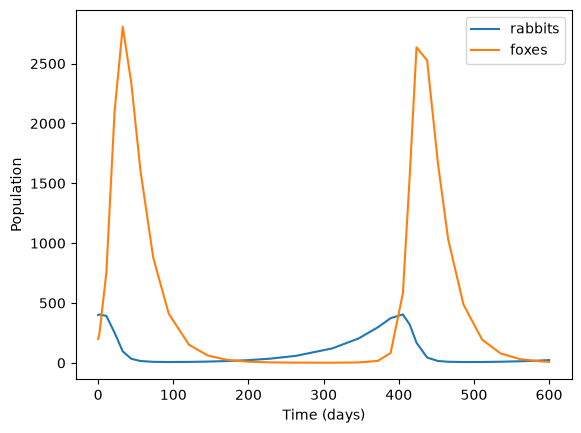

In [7]:
def dydt(t, y):
    R, F = y
    dRdt = k1 * R - k2 * R * F
    dFdt = k3 * R * F - k4 * F
    return [dRdt, dFdt]
sol = solve_ivp(dydt, (0, 600), y0)
print(sol.success, sol.nfev, len(sol.t))

plt.plot(sol.t, sol.y[0], label = "rabbits")
plt.plot(sol.t, sol.y[1], label = "foxes")
plt.xlabel("Time (days)")
plt.ylabel("Population")
plt.legend()
plt.show()


Your plot is probably jagged. Why? Fix it in two ways: with `t_eval`, and with
`dense_output=True`. Does either one change `sol.nfev`?

242 242 242


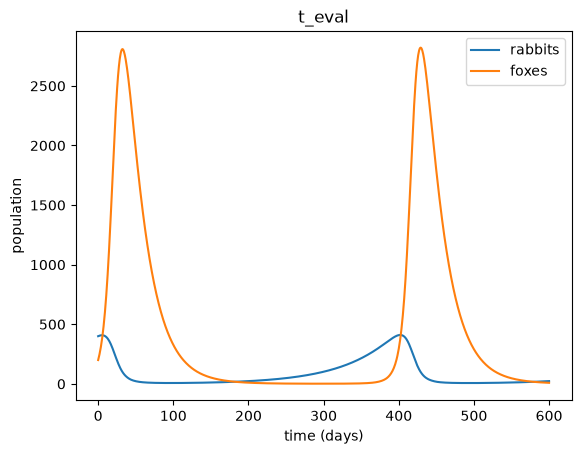

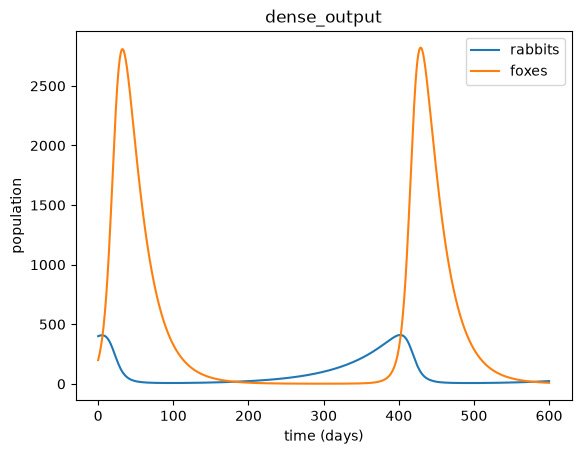

In [11]:
t_plot = np.linspace(0, 600, 1000)
sol_a = solve_ivp(dydt, (0, 600), y0, t_eval=t_plot)

sol_b = solve_ivp(dydt, (0, 600), y0, dense_output=True)
y_plot = sol_b.sol(t_plot)

print(sol.nfev, sol_a.nfev, sol_b.nfev)

plt.plot(sol_a.t, sol_a.y[0], label="rabbits")
plt.plot(sol_a.t, sol_a.y[1], label="foxes")
plt.xlabel("time (days)")
plt.ylabel("population")
plt.title("t_eval")
plt.legend()
plt.show()

plt.plot(t_plot, y_plot[0], label="rabbits")
plt.plot(t_plot, y_plot[1], label="foxes")
plt.xlabel("time (days)")
plt.ylabel("population")
plt.title("dense_output")
plt.legend()
plt.show()

## 2. The phase portrait

Solve to 1200 days, three full cycles, and plot foxes against rabbits. The exact
solution is a closed loop, traced over and over. Is yours?

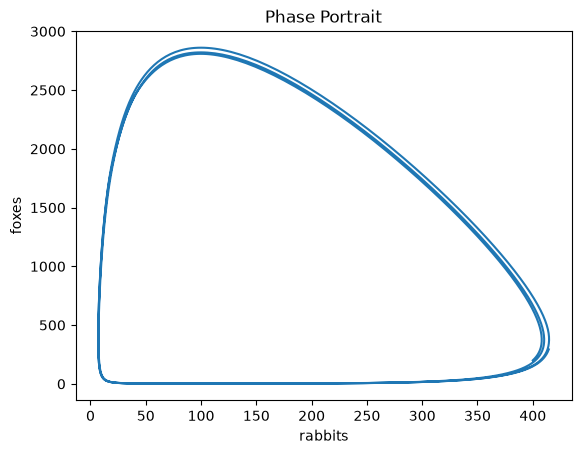

In [20]:
t_plot = np.linspace(0, 1200, 4000)
sol = solve_ivp(dydt, (0, 1200), y0, t_eval=t_plot)

plt.plot(sol.y[0], sol.y[1])
plt.xlabel("rabbits")
plt.ylabel("foxes")
plt.title("Phase Portrait")
plt.show()


I got a closed loop traced over and over

## 3. The height of each fox peak, using events

Searching `sol.y` for the largest value gives you the largest value **at the times
the solver happened to stop**, which won't be exactly at the peak. `solve_ivp` can
find the exact moment instead, with an *event*: a function `g(t, y)` that it
watches. It reports every time `g` passes through zero.

The foxes peak when $dF/dt$ changes from positive to negative. Since
$dF/dt = F(k_3 R - k_4)$ and $F > 0$, that happens when $k_3 R - k_4$ goes from
positive to negative. So:

```python
def fox_peak(t, y):
    R, F = y
    return k3 * R - k4

fox_peak.direction = -1   # only count it when g is decreasing through zero

sol = solve_ivp(dydt, (0, 1200), y0, events=fox_peak)
sol.t_events[0]          # the times of the peaks
sol.y_events[0]          # the [R, F] values at each one
```

Print the time and height of each fox peak, with the default tolerances. Compare
with the Euler peaks above. How many function evaluations did it take, compared
with Euler's 12,000 or 240,000 steps?

In [26]:
def fox_peak(t, y):
    R, F = y
    return k3 * R - k4
fox_peak.direction = -1

sol = solve_ivp(dydt, (0, 1200), y0, events=fox_peak)
print(sol.t_events[0])
print(sol.y_events[0])
print(sol.nfev)

[ 32.32034105 429.10196041 828.51594358]
[[ 100.         2808.62545428]
 [ 100.         2820.99697305]
 [ 100.         2860.87836248]]
440


first row is the time of fox peak, next 3 rows are rabit population (100) and fox population at peak fox populations. Euler 240,000 steps has a significantly smaller difference between max peak and min peak but uses a lot more evaluations. Max-min for solve-ivp is 2860-2808 = 52. 

## 4. Required accuracy: `rtol`

The true peaks are all the same height. So the *drift*, last peak minus first, is a
measure of the error, and we don't need the exact answer to find it.

Loop over `rtol` from `1e-3` to `1e-10`, keeping `atol = 1e-8`. For each value
record the drift and `sol.nfev`. Then make two log-log plots: |drift| against
`rtol`, and |drift| against `nfev`. The second is called a *work–precision
diagram*.

- How tight must `rtol` be for the peaks to agree to within one fox? To within
  0.01 of a fox?
- What is the height of the fox peak, to as many significant figures as you can
  justify? How do you know?
- Euler with 240,000 steps had a drift of 3.7 foxes. How many function evaluations
  does `solve_ivp` need to do better than that?

rtol		drift		nfev
0.001 440 2808.6254728571867 2860.8198043276216 52.19433147043492
0.0001 656 2804.082088802565 2805.681834068286 1.5997452657211397
1e-05 956 2803.855910644135 2803.937372045181 0.08146140104599908
1e-06 1424 2803.866741111437 2803.87700973988 0.01026862844310017
1e-07 2090 2803.870416693182 2803.869999761482 -0.0004169316998741124
1e-08 3152 2803.870128538871 2803.870091133186 -3.740568490684382e-05
1e-09 4634 2803.8700988705186 2803.8700997142623 8.437436918029562e-07
1e-10 6254 2803.870096107227 2803.87009534064 -7.665867087780498e-07


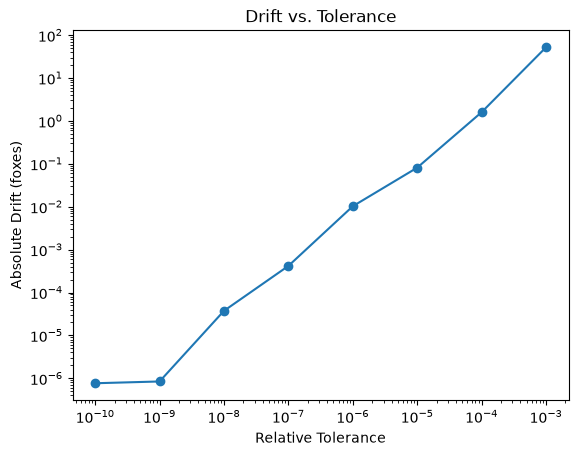

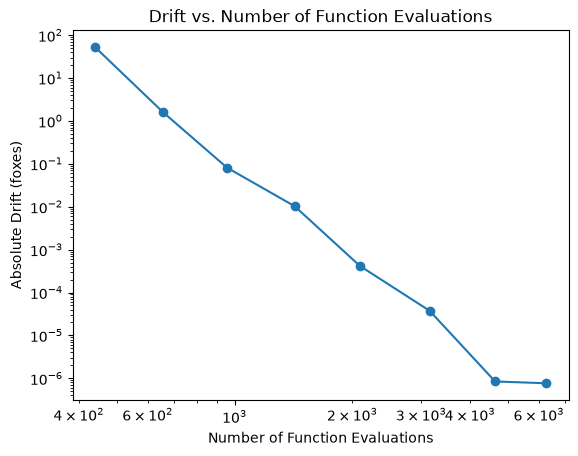

In [30]:
rtols = [1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8, 1e-9, 1e-10]
drifts = []
nfevs = []
print("rtol\t\tdrift\t\tnfev")
for rtol in rtols:
    sol = solve_ivp(dydt, (0, 1200), y0, events = fox_peak, rtol = rtol, atol= 1e-8)
    peaks = sol.y_events[0][:, 1]
    drift = peaks[-1] - peaks[0]
    drifts.append(drift)
    nfevs.append(sol.nfev)
    print(rtol, sol.nfev, peaks[0], peaks[-1], drift)

plt.loglog(rtols, np.abs(drifts), marker='o')
plt.xlabel('Relative Tolerance')
plt.ylabel('Absolute Drift (foxes)')
plt.title('Drift vs. Tolerance')
plt.show()

plt.loglog(nfevs, np.abs(drifts), marker='o')
plt.xlabel('Number of Function Evaluations')
plt.ylabel('Absolute Drift (foxes)')
plt.title('Drift vs. Number of Function Evaluations')
plt.show()


within one fox: rtol of 10^-5, within 0.01 of a fox: rtol of 10^-7
2803.8701 foxes, I know because this value is rounded up from relative tolerance of 10^-9 at which the absolute drift begins to plateu
240,000 steps gives 3.7 drift for euler. Rtol has drift of 1.6 with 656 evaluations (minimum function evaluations to get lowest drift)

## 5. `atol`, and how few foxes is too few?

What is the **smallest** number of foxes during the cycle, and of rabbits? (Use
`dense_output=True` and a fine grid of times, or another event.)

Now someone argues: "A fraction of a fox is meaningless, so I'll set `atol = 1`."
Try it, with `rtol = 1e-6`. Then try `atol = 10`. What happens to the peaks? Explain
why, using the formula for the error tolerance, $\text{atol} + \text{rtol}\,|y|$.

And about the model itself: what does a population of under two foxes mean? Would a
real population survive that trough? (Lecture 10, kinetic Monte Carlo, is one way
to model that properly.)

In [31]:
sol=solve_ivp(dydt, (0, 1200), y0, dense_output=True, rtol=1e-8, atol=1e-8)
t_plot = np.linspace(0, 1200, 10000)
R, F = sol.sol(t_plot)
print("rabbit min:", R.min())
print("fox min:", F.min())

for atol in [1e-8, 1, 10]:
    sol = solve_ivp(dydt, (0, 1200), y0, events=fox_peak, rtol=1e-6, atol=atol)
    peaks = sol.y_events[0][:, 1]
    print(atol, sol.nfev, peaks)

rabbit min: 7.426072522180815
fox min: 1.5936369523155658
1e-08 1424 [2803.86674111 2803.87208144 2803.87700974]
1 368 [2804.04832059 2675.90606982 2649.84542836 2531.29435906]
10 344 [2804.20992471 2593.16364437 2544.83632657 2315.84125304]


Smallest number of rabbits is 7(.4) and smallest number of foxes is 1(.6). The peaks differ greatly 2804 to 2531 with atol = 1 and even more 2804 to 2315 with atol=10. atol + rtol * |y| shows the allowed error. if the product of the rtol (1e^-6) and peak fox (2804) is around 0.002804, a higher atol such as = 10 will increase allowed error and overwhelm the rtol * y term. A population of under two foxes means a real population would most likely not survive that trough given the possibility (with a high atol) of an error that is greater than the population of foxes at its minimum. 

## 6. Which method?

At `rtol = 1e-8, atol = 1e-8`, compare `method=` `"RK45"`, `"DOP853"`, `"LSODA"`,
`"BDF"` and `"Radau"`: drift and `nfev` for each. Which is cheapest for this
problem? Is this problem stiff? How can you tell?

In [32]:
for method in ["RK45", "DOP853", "LSODA", "BDF", "Radau"]:
    sol = solve_ivp(dydt, (0, 1200), y0, method=method, events=fox_peak, rtol=1e-8, atol=1e-8)
    peaks = sol.y_events[0][:, 1]
    print(method, sol.nfev, peaks[-1] - peaks[0])

RK45 3152 -3.740568490684382e-05
DOP853 2063 -1.9759945644182153e-06
LSODA 1257 -0.00035048182053287746
BDF 4675 -0.001119456985634315
Radau 14273 1.1756446838262491e-07


Cheapest: LSODA has the least steps
. Problem is not stiff because RK45 has lower number of evaluations compared to BDF and Radau

## Stretch problems

**(a)** For this system the quantity
$V = k_3 R - k_4 \ln R + k_2 F - k_1 \ln F$ stays exactly constant. (Differentiate
it and substitute the two ODEs to check.) That's why the orbit is closed. Plot
how much $V$ changes over 1200 days for a few values of `rtol`. Is it a better
measure of the error than the peak drift?

**(b)** Re-run with $k_3 = 0.00004$ day$^{-1}$ rabbits$^{-1}$ for 800 days, as in
Lecture 3. The fixed point moves from (100, 375) to (1000, 375). Do your
conclusions about `rtol` change?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors. Commit and
push. Then check on GitHub that your fork shows your latest commit, and that the
notebook displays with its plots.